# 06 — Error analysis and interpretation

This notebook looks closely at the preferred model (gradient boosting, 400 rounds, on TF-IDF word features):
1. **Where it goes wrong**, using out-of-fold predictions on the training set: every training book is predicted by a model that never saw it (or its author), using the same 5 folds as before.
2. **Error slices with uncertainty**: performance per period and for books near a period boundary, with book counts and 95% confidence intervals.
3. **The 1850–1899 / 1900–1918 confusion**, the most common mistake.
4. **Final test-set performance with a confidence interval**, for the model card. No decisions are made from the test set here; the model was fixed in notebook 03.

## Setup

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, ConfusionMatrixDisplay

from src import config

In [2]:
train = pd.read_csv(config.PROCESSED_DIR / "train.csv")
test = pd.read_csv(config.PROCESSED_DIR / "test.csv")
PERIODS = ["pre-1750", "1750-1799", "1800-1849", "1850-1899", "1900-1918"]
INDEX = {p: i for i, p in enumerate(PERIODS)}

cv = StratifiedGroupKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)

def tfidf():
    return TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z]{2,}\b", min_df=10)

def boosting_model():
    return make_pipeline(tfidf(), GradientBoostingClassifier(
        n_estimators=400, learning_rate=0.1, max_depth=3, max_features="sqrt", random_state=config.RANDOM_STATE))

print("Train:", train.shape, " Test:", test.shape)

Train: (288, 6)  Test: (71, 6)


## Out-of-fold predictions

`cross_val_predict` trains on 4 folds and predicts the 5th, for each fold in turn, so every training book gets exactly one prediction from a model that has not seen it. This gives 288 predictions to analyse instead of 71 test books, without touching the test set.

`error_size` is how many periods away the prediction is (1 = a neighbouring period).

In [3]:
train["pred"] = cross_val_predict(boosting_model(), train["excerpt"], train["period"],
                                  groups=train["group"], cv=cv)
train["error_size"] = (train["period"].map(INDEX) - train["pred"].map(INDEX)).abs()

errors = train[train["error_size"] > 0]
print(f"Out-of-fold macro-F1: {f1_score(train['period'], train['pred'], average='macro'):.3f}  "
      f"accuracy: {accuracy_score(train['period'], train['pred']):.3f}")
print(f"Errors: {len(errors)} of {len(train)};  in a neighbouring period: {(errors['error_size'] == 1).mean():.0%}")
errors["error_size"].value_counts().sort_index()

Out-of-fold macro-F1: 0.515  accuracy: 0.497
Errors: 145 of 288;  in a neighbouring period: 82%


error_size
1    119
2     20
3      4
4      2
Name: count, dtype: int64

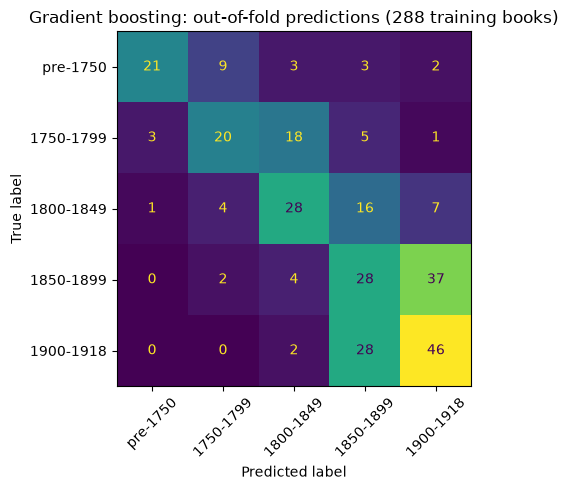

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(train["period"], train["pred"], labels=PERIODS,
                                        xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title("Gradient boosting: out-of-fold predictions (288 training books)")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "confusion_oof_boosting.png", dpi=150)
plt.show()

## Error slices with uncertainty

Each slice reports the number of books and authors, the accuracy (for a period slice this is the recall: the share of that period's books predicted correctly), and a **95% confidence interval** from a bootstrap.

The bootstrap resamples authors, not books, 1,000 times: books by the same author tend to be right or wrong together, so resampling single books would make the intervals look narrower than they really are.

Besides the five periods, books are also split by **distance from the nearest period boundary** (1750, 1800, 1850, 1900): a book from 1898 is likely to read much like one from 1902, so errors should be more common near a boundary.

In [5]:
rng = np.random.default_rng(config.RANDOM_STATE)

def group_bootstrap(df, stat, n=1000):
    """95% interval for stat(df), resampling authors (groups) with replacement."""
    rows_of = df.groupby("group").indices
    authors = list(rows_of)
    values = []
    for _ in range(n):
        pick = rng.choice(len(authors), size=len(authors), replace=True)
        rows = np.concatenate([rows_of[authors[i]] for i in pick])
        values.append(stat(df.iloc[rows]))
    return np.percentile(values, [2.5, 97.5])

def accuracy(d):
    return (d["period"] == d["pred"]).mean()

def slice_row(name, d):
    lo, hi = group_bootstrap(d, accuracy)
    errs = d[d["error_size"] > 0]
    return {"slice": name, "books": len(d), "authors": d["group"].nunique(),
            "accuracy": round(accuracy(d), 3), "95% CI": f"{lo:.2f}–{hi:.2f}",
            "errors in neighbouring period": f"{(errs['error_size'] == 1).mean():.0%}" if len(errs) else "–"}

BOUNDARIES = [1750, 1800, 1850, 1900]
train["years_from_boundary"] = train["publication_date"].apply(lambda yr: min(abs(yr - b) for b in BOUNDARIES))
near = train["years_from_boundary"] <= 10

rows = [slice_row("All training books", train)]
rows += [slice_row(p, train[train["period"] == p]) for p in PERIODS]
rows += [slice_row("Within 10 years of a boundary", train[near]),
         slice_row("More than 10 years from a boundary", train[~near])]
slices = pd.DataFrame(rows)
slices

,slice,books,authors,accuracy,95% CI,errors in neighbouring period
0,All training books,288,275,0.497,0.44–0.55,82%
1,pre-1750,38,35,0.553,0.38–0.72,53%
2,1750-1799,47,45,0.426,0.29–0.57,78%
3,1800-1849,56,54,0.500,0.38–0.64,71%
4,1850-1899,71,69,0.394,0.28–0.52,95%
5,1900-1918,76,73,0.605,0.50–0.72,93%
6,Within 10 years of a boundary,136,133,0.397,0.32–0.47,82%
7,More than 10 years from a boundary,152,147,0.586,0.50–0.66,83%


## The 1850–1899 / 1900–1918 confusion

These two periods are the largest and are next to each other. The books confused between them are listed below with their publication year, to see whether the mistakes cluster around 1900.

In [6]:
late = train[train["period"].isin(["1850-1899", "1900-1918"])]
mixed = late[late["pred"].isin(["1850-1899", "1900-1918"]) & (late["period"] != late["pred"])]
correct = late[late["period"] == late["pred"]]

print(f"{len(mixed)} of {len(late)} books from these two periods are predicted as the other one")
print(f"Median years from 1900: confused {mixed['publication_date'].sub(1900).abs().median():.0f}, "
      f"correct {correct['publication_date'].sub(1900).abs().median():.0f}")
mixed[["title", "publication_date", "period", "pred"]].sort_values("publication_date")

65 of 147 books from these two periods are predicted as the other one
Median years from 1900: confused 10, correct 11


,title,publication_date,period,pred
158,Off-Hand Sketches by T. S. Arthur,1851,1850-1899,1900-1918
174,The Lady's Country Companion by Jane Webb Loudon,1852,1850-1899,1900-1918
152,Address to the People of the United States tog...,1855,1850-1899,1900-1918
172,Aaron Trow by Anthony Trollope,1864,1850-1899,1900-1918
160,Feats on the Fiord by Harriet Martineau,1865,1850-1899,1900-1918
...,...,...,...,...
263,The Problem of Truth by H. Wildon Carr,1913,1900-1918,1850-1899
287,The Snakes of Europe by G. A. Boulenger,1913,1900-1918,1850-1899
273,Cornwall's Wonderland by Mabel Quiller-Couch,1914,1900-1918,1850-1899
267,Frank Forester by Herbert Strang,1915,1900-1918,1850-1899


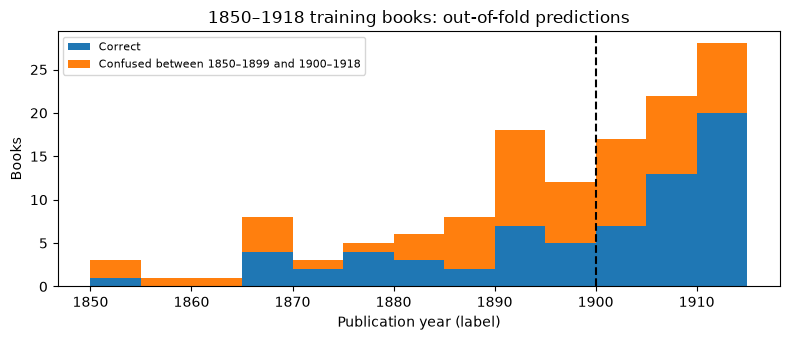

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = range(1850, 1920, 5)
ax.hist([correct["publication_date"], mixed["publication_date"]], bins=bins, stacked=True,
        label=["Correct", "Confused between 1850–1899 and 1900–1918"])
ax.axvline(1900, color="black", linestyle="--")
ax.set_xlabel("Publication year (label)")
ax.set_ylabel("Books")
ax.set_title("1850–1918 training books: out-of-fold predictions")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "confusion_1850_1900_by_year.png", dpi=150)
plt.show()

## Final test-set performance with uncertainty

The final model from notebook 03 (boosting trained on all 288 training books, fixed seed) is rebuilt and its test predictions are recomputed, so the model card can report a confidence interval. The macro-F1 must match notebook 03 (0.519). These numbers are **reported only**: nothing is tuned or chosen from them.

In [8]:
final_model = boosting_model().fit(train["excerpt"], train["period"])
test["pred"] = final_model.predict(test["excerpt"])
test["error_size"] = (test["period"].map(INDEX) - test["pred"].map(INDEX)).abs()

def macro_f1(d):
    return f1_score(d["period"], d["pred"], average="macro", labels=PERIODS, zero_division=0)

lo, hi = group_bootstrap(test, macro_f1)
print(f"Test macro-F1: {macro_f1(test):.3f} (95% CI {lo:.2f}–{hi:.2f}, resampling authors)")
lo, hi = group_bootstrap(test, accuracy)
print(f"Test accuracy: {accuracy(test):.3f} (95% CI {lo:.2f}–{hi:.2f})")

pd.DataFrame([slice_row(p, test[test["period"] == p]) for p in PERIODS])

Test macro-F1: 0.519 (95% CI 0.37–0.63, resampling authors)
Test accuracy: 0.507 (95% CI 0.39–0.62)


,slice,books,authors,accuracy,95% CI,errors in neighbouring period
0,pre-1750,10,6,0.700,0.33–0.90,33%
1,1750-1799,11,11,0.455,0.18–0.73,83%
2,1800-1849,14,14,0.357,0.14–0.64,67%
3,1850-1899,17,17,0.353,0.12–0.59,91%
4,1900-1918,19,19,0.684,0.47–0.89,100%


In [9]:
cols = ["id", "title", "publication_date", "period", "group", "pred", "error_size"]
train[cols].to_csv(config.ROOT / "reports" / "oof_predictions_boosting.csv", index=False)
slices.to_csv(config.ROOT / "reports" / "error_slices.csv", index=False)
print("Saved out-of-fold predictions and error slices")

Saved out-of-fold predictions and error slices
